# Data Analysis

Notebook for analyzing the data annotated by teachers; goes beyond the basic stats in `annotation_stats.ipynb`.

In [7]:
import json
import statistics
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Find the repo root (the folder with AGENTS.md) so the build package imports.
REPO_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "AGENTS.md").exists()
)
sys.path.insert(0, str(REPO_ROOT))

from tutormoments_build.v2.build_ground_truth import (  # noqa: E402
    DEFAULT_EXCLUDED_ANNOTATORS,
    answered_payload,
    latest_annotations,
    load_excluded_annotators,
)

GROUND_TRUTH_DIR = REPO_ROOT / "data" / "ground_truth"
# The split files only: other build outputs (e.g. student_state.jsonl) share the dir.
GROUND_TRUTH_FILES = [
    GROUND_TRUTH_DIR / "iteration.jsonl",
    GROUND_TRUTH_DIR / "test.jsonl",
]
SOURCE_DIR = REPO_ROOT / "data" / "v2_annotations" / "source"
ANNOTATION_FILES = [
    SOURCE_DIR / "tutoring_provider_a_annotations.jsonl",
    SOURCE_DIR / "tutoring_provider_c_annotations.jsonl",
]


def read_jsonl(path: Path) -> list[dict]:
    with open(path, encoding="utf-8") as fh:
        return [json.loads(line) for line in fh if line.strip()]

## Student Outcomes

In the cell below, we are interested in examining the distribution of student outcome ratings (engagement and success) for the following: 
- scaffolding-appropriate moments (scaffold_only + scaffold_maj) where the human tutor does or doesn't scaffold
- rigor-appropriate moments (rigor_maj + rigor_only) where the human tutor does or doesn't push for rigor 

Input: 
- `data/ground_truth` files 

To aggregate teachers' student outcome ratings (in the original `tutoring_provider_a_annotations.jsonl` and `tutoring_provider_c_annotations.jsonl` files), average the ratings for each moment. 

Map success to: 
- 0: there is no problem-related success/progress or not enough evidence
- 1: there is problem-related success/progress, but it is not meaningful
- 2: there is meaningful problem-related success/progress

Map engagement to: 
- 1: high or good amount of cognitive engagement
- 0: low cognitive engagement or not enough evidence

We plot engagement and success separately; x-axis is situation type, and hue is whether the human tutor makes the appropriate move. 

ground-truth moments: 1271
  skipped (not scaffolding/rigor-appropriate): 28
  skipped (no outcome ratings): 0
  analyzed: 1243
raters per moment: {3: 903, 4: 340}


engagement             success        \
                                              count  mean   std   count  mean   
situation               tutor_makes_move                                        
Rigor-appropriate       No                      224  0.43  0.38     224  1.12   
                        Yes                     434  0.81  0.31     434  1.67   
Scaffolding-appropriate No                       25  0.50  0.39      25  0.80   
                        Yes                     560  0.55  0.40     560  1.23   

                                                
                                           std  
situation               tutor_makes_move        
Rigor-appropriate       No                0.58  
                        Yes               0.52  
Scaffolding-appropriate No                0.72  
                        Yes               0.67

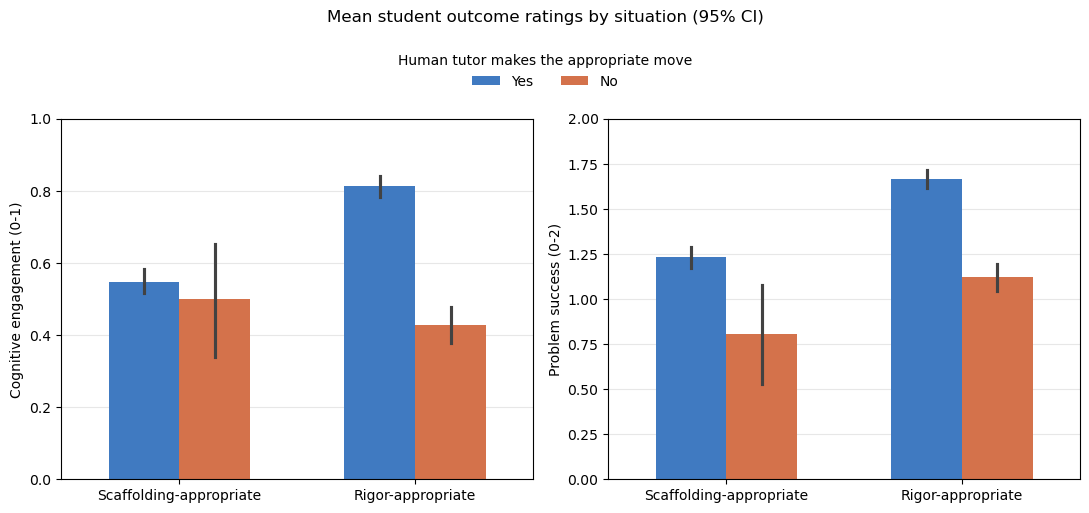

In [8]:
# --- Rating scales -----------------------------------------------------------

SUCCESS_SCORES = {
    "no_success": 0,
    "not_enough_evidence": 0,
    "not_meaningful": 1,
    "meaningful_success": 2,
}
ENGAGEMENT_SCORES = {
    "high_or_good": 1,
    "low": 0,
    "not_enough_evidence": 0,
}

# Each situation group: the situation types it pools, and the ground-truth
# label that says whether the human tutor made that group's appropriate move.
SITUATION_GROUPS = {
    "Scaffolding-appropriate": {
        "situation_types": {"scaffold_only", "scaffold_maj"},
        "move_label": "scaffolding_present",
    },
    "Rigor-appropriate": {
        "situation_types": {"rigor_only", "rigor_maj"},
        "move_label": "rigor_present",
    },
}


def situation_group(situation_type: str) -> str | None:
    """The group a situation type belongs to, or None (e.g. fifty_fifty)."""
    for group, spec in SITUATION_GROUPS.items():
        if situation_type in spec["situation_types"]:
            return group
    return None


# --- Average each moment's student outcome ratings ---------------------------

excluded_annotators = load_excluded_annotators(
    str(REPO_ROOT / DEFAULT_EXCLUDED_ANNOTATORS)
)


def average_outcome_ratings(annotations: list[dict]) -> dict | None:
    """Mean engagement and success over the teachers who rated the outcome.

    Every annotator counts, as in build_ground_truth: each annotator's latest
    revision, project staff dropped, adjudicators' answers read from their
    "final" section, and anyone who threw the moment out abstaining.
    """
    answered = [
        answered_payload(annotation)
        for annotation in latest_annotations(annotations, excluded_annotators)
    ]
    ratings = [
        payload["result"] for payload in answered if payload and payload.get("result")
    ]
    if not ratings:
        return None
    return {
        "engagement": statistics.mean(
            ENGAGEMENT_SCORES[r["cognitive_engagement"]] for r in ratings
        ),
        "success": statistics.mean(
            SUCCESS_SCORES[r["problem_success"]] for r in ratings
        ),
        "n_raters": len(ratings),
    }


outcomes_by_moment = {}
for path in ANNOTATION_FILES:
    for record in read_jsonl(path):
        if "moment" not in record:  # transcript with no key moments
            continue
        outcome = average_outcome_ratings(record["annotations"])
        if outcome is not None:
            outcomes_by_moment[record["moment"]["moment_id"]] = outcome

# --- Join outcomes onto the ground-truth moments -----------------------------

ground_truth = [
    moment
    for path in GROUND_TRUTH_FILES
    for moment in read_jsonl(path)
]

rows = []
skipped_situation = 0
missing_outcome = 0
for moment in ground_truth:
    group = situation_group(moment["situation_type"])
    if group is None:
        skipped_situation += 1
        continue
    outcome = outcomes_by_moment.get(moment["moment_id"])
    if outcome is None:
        missing_outcome += 1
        continue
    makes_move = moment["labels"][SITUATION_GROUPS[group]["move_label"]]
    rows.append(
        {
            "moment_id": moment["moment_id"],
            "source": moment["source"],
            "situation": group,
            "tutor_makes_move": "Yes" if makes_move else "No",
            **outcome,
        }
    )
outcomes = pd.DataFrame(rows)

print(f"ground-truth moments: {len(ground_truth)}")
print(f"  skipped (not scaffolding/rigor-appropriate): {skipped_situation}")
print(f"  skipped (no outcome ratings): {missing_outcome}")
print(f"  analyzed: {len(outcomes)}")
print(
    f"raters per moment: {outcomes['n_raters'].value_counts().sort_index().to_dict()}"
)

summary = outcomes.groupby(["situation", "tutor_makes_move"])[
    ["engagement", "success"]
].agg(["count", "mean", "std"])
display(summary.round(2))

# --- Plot --------------------------------------------------------------------

SITUATION_ORDER = list(SITUATION_GROUPS)
MOVE_ORDER = ["Yes", "No"]
MOVE_COLORS = {"Yes": "#2a78d6", "No": "#eb6834"}
OUTCOME_AXES = {
    "engagement": ("Cognitive engagement (0-1)", (0, 1)),
    "success": ("Problem success (0-2)", (0, 2)),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (outcome, (ylabel, ylim)) in zip(axes, OUTCOME_AXES.items()):
    sns.barplot(
        data=outcomes,
        x="situation",
        y=outcome,
        hue="tutor_makes_move",
        order=SITUATION_ORDER,
        hue_order=MOVE_ORDER,
        palette=MOVE_COLORS,
        errorbar=("ci", 95),
        seed=0,  # fixed bootstrap so the CIs are reproducible
        width=0.6,
        ax=ax,
    )
    ax.set(xlabel="", ylabel=ylabel, ylim=ylim)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Human tutor makes the appropriate move",
    loc="upper center",
    bbox_to_anchor=(0.5, 1.06),
    ncol=len(MOVE_ORDER),
    frameon=False,
)
fig.suptitle("Mean student outcome ratings by situation (95% CI)", y=1.13)
fig.tight_layout()
plt.show()

## Tutor Actions

Distribution of adjudicators' checkboxes of what tutor action was performed. When there are two adjudicators for a moment, their checkboxes are merged. 

One plot for scaffolding_present, one plot for rigor_present (based on adjudicators' judgements).

ground-truth moments: 1271
  with an adjudicator answer: 1271
  adjudicators per moment: {1: 908, 2: 363}
scaffolding_present: 822 moments (adjudicators split on 40)
rigor_present: 488 moments (adjudicators split on 37)


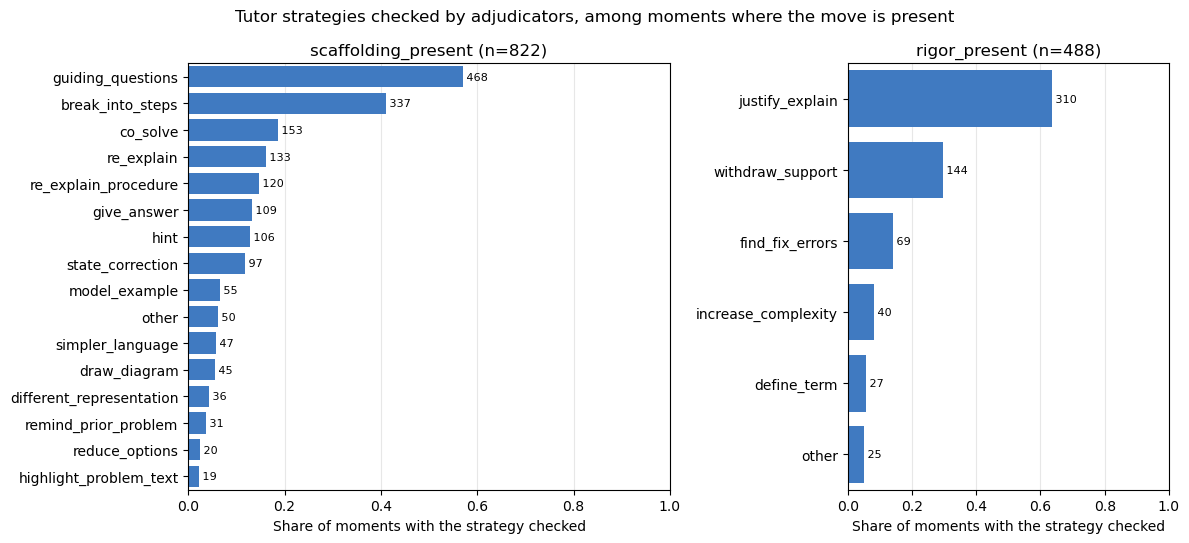

In [9]:
# --- Merge each moment's adjudicator checkboxes ------------------------------

# Each tutor move: its present flag and checkbox list in the adjudicator's
# "action" section, and the free-text field behind the "Other" checkbox.
TUTOR_MOVES = {
    "scaffolding_present": ("scaffolding_strategies", "scaffolding_strategy_other"),
    "rigor_present": ("rigor_strategies", "rigor_strategy_other"),
}
OTHER = "other"


def adjudicator_actions(annotations: list[dict]) -> list[dict]:
    """The "action" section of each adjudicator who answered the moment.

    Same filtering as build_ground_truth: latest revision per annotator, staff
    dropped, and an adjudicator who threw the moment out abstains.
    """
    answered = [
        answered_payload(annotation)
        for annotation in latest_annotations(annotations, excluded_annotators)
        if annotation.get("role") == "adjudicator"
    ]
    return [payload["action"] for payload in answered if payload]


def merged_strategies(actions: list[dict], move: str) -> set[str] | None:
    """Union of the checkboxes from adjudicators who marked the move present.

    None when no adjudicator marked it present.
    """
    strategies_key, other_key = TUTOR_MOVES[move]
    marked = [action for action in actions if action.get(move)]
    if not marked:
        return None
    merged = set()
    for action in marked:
        merged.update(action.get(strategies_key) or [])
        if (action.get(other_key) or "").strip():
            merged.add(OTHER)
    return merged


actions_by_moment = {}
for path in ANNOTATION_FILES:
    for record in read_jsonl(path):
        if "moment" not in record:  # transcript with no key moments
            continue
        actions = adjudicator_actions(record["annotations"])
        if actions:
            actions_by_moment[record["moment"]["moment_id"]] = actions

# --- Tally strategies over the ground-truth moments --------------------------

adjudicated = [m for m in ground_truth if m["moment_id"] in actions_by_moment]
print(f"ground-truth moments: {len(ground_truth)}")
print(f"  with an adjudicator answer: {len(adjudicated)}")
print(
    "  adjudicators per moment: "
    f"{pd.Series([len(actions_by_moment[m['moment_id']]) for m in adjudicated]).value_counts().sort_index().to_dict()}"
)

strategy_rows = []
n_present = {}
for move in TUTOR_MOVES:
    present = 0
    split = 0  # two adjudicators, only one marked the move present
    for moment in adjudicated:
        actions = actions_by_moment[moment["moment_id"]]
        strategies = merged_strategies(actions, move)
        if strategies is None:
            continue
        present += 1
        split += len({bool(a.get(move)) for a in actions}) > 1
        strategy_rows += [
            {"move": move, "moment_id": moment["moment_id"], "strategy": s}
            for s in strategies
        ]
    n_present[move] = present
    print(f"{move}: {present} moments (adjudicators split on {split})")

strategies = pd.DataFrame(strategy_rows)
strategy_share = (
    strategies.groupby(["move", "strategy"])
    .size()
    .rename("moments")
    .reset_index()
)
strategy_share["share"] = strategy_share["moments"] / strategy_share["move"].map(
    n_present
)

# --- Plot --------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    len(TUTOR_MOVES),
    figsize=(12, 5.5),
    gridspec_kw={"width_ratios": [3, 2]},
)
for ax, move in zip(axes, TUTOR_MOVES):
    data = strategy_share[strategy_share["move"] == move].sort_values(
        "share", ascending=False
    )
    sns.barplot(data=data, x="share", y="strategy", color="#2a78d6", ax=ax)
    for patch, count in zip(ax.patches, data["moments"]):
        ax.annotate(
            f" {count}",
            (patch.get_width(), patch.get_y() + patch.get_height() / 2),
            va="center",
            fontsize=8,
        )
    ax.set(
        title=f"{move} (n={n_present[move]})",
        xlabel="Share of moments with the strategy checked",
        ylabel="",
        xlim=(0, 1),
    )
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

fig.suptitle(
    "Tutor strategies checked by adjudicators, among moments where the move is present"
)
fig.tight_layout()
plt.show()